In [168]:
import requests
import json
from pprint import pprint
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [5]:
#! pip install requests

In [35]:
response = requests.get("https://openbookrank.com/api/v1/rankings/fantasy.json")
response

<Response [200]>

In [37]:
for r in response.json(): #the way it works in python
    print(r)

category
name
names
count
url
api
priorMean
snapshot
license
items


In [62]:
#for r in response.json()["items"]:
#    print(r['title'], r['score'], r['confidence'], r['year'])

In [43]:
bookrank_df = pd.DataFrame(response.json()['items'])

In [44]:
bookrank_df

,rank,id,slug,title,author,year,score,ratings,confidence,url,api
0,1,obr:work:words-of-radiance,words-of-radiance,Words of Radiance,Brandon Sanderson,2014.0,9.37,3473,0.959,https://openbookrank.com/en/book/words-of-radi...,https://openbookrank.com/api/v1/books/words-of...
1,2,obr:work:the-way-of-kings,the-way-of-kings,The Way of Kings,Brandon Sanderson,2010.0,9.20,3927,0.964,https://openbookrank.com/en/book/the-way-of-kings,https://openbookrank.com/api/v1/books/the-way-...
2,3,obr:work:the-hero-of-ages,the-hero-of-ages,Mistborn: The Hero of Ages,Brandon Sanderson,2008.0,9.10,4191,0.966,https://openbookrank.com/en/book/the-hero-of-ages,https://openbookrank.com/api/v1/books/the-hero...
3,4,obr:work:the-return-of-the-king,the-return-of-the-king,The Return of the King,J. R. R. Tolkien,1955.0,9.10,2111,0.934,https://openbookrank.com/en/book/the-return-of...,https://openbookrank.com/api/v1/books/the-retu...
4,5,obr:work:the-lord-of-the-rings,the-lord-of-the-rings,The Lord of the Rings,J. R. R. Tolkien,1954.0,9.05,2111,0.934,https://openbookrank.com/en/book/the-lord-of-t...,https://openbookrank.com/api/v1/books/the-lord...
...,...,...,...,...,...,...,...,...,...,...,...
1395,1396,obr:work:breaking-dawn,breaking-dawn,Breaking Dawn,Stephenie Meyer,2008.0,6.42,1875,0.927,https://openbookrank.com/en/book/breaking-dawn,https://openbookrank.com/api/v1/books/breaking...
1396,1397,obr:work:eclipse,eclipse,Eclipse,Stephenie Meyer,2007.0,6.37,1877,0.927,https://openbookrank.com/en/book/eclipse,https://openbookrank.com/api/v1/books/eclipse....
1397,1398,obr:work:harry-potter-and-the-cursed-child,harry-potter-and-the-cursed-child,Harry Potter and the Cursed Child,Jack Thorne,2016.0,6.32,2076,0.933,https://openbookrank.com/en/book/harry-potter-...,https://openbookrank.com/api/v1/books/harry-po...
1398,1399,obr:work:twilight,twilight,Twilight,Stephenie Meyer,2005.0,6.18,4222,0.966,https://openbookrank.com/en/book/twilight,https://openbookrank.com/api/v1/books/twilight...


In [76]:
bookrank_clean_df = bookrank_df[[
    'rank',
    'title',
    'author',
    'year',
    'score',
    'ratings',
    'confidence'
]]
bookrank_clean_df

,rank,title,author,year,score,ratings,confidence
0,1,Words of Radiance,Brandon Sanderson,2014.0,9.37,3473,0.959
1,2,The Way of Kings,Brandon Sanderson,2010.0,9.20,3927,0.964
2,3,Mistborn: The Hero of Ages,Brandon Sanderson,2008.0,9.10,4191,0.966
3,4,The Return of the King,J. R. R. Tolkien,1955.0,9.10,2111,0.934
4,5,The Lord of the Rings,J. R. R. Tolkien,1954.0,9.05,2111,0.934
...,...,...,...,...,...,...,...
1395,1396,Breaking Dawn,Stephenie Meyer,2008.0,6.42,1875,0.927
1396,1397,Eclipse,Stephenie Meyer,2007.0,6.37,1877,0.927
1397,1398,Harry Potter and the Cursed Child,Jack Thorne,2016.0,6.32,2076,0.933
1398,1399,Twilight,Stephenie Meyer,2005.0,6.18,4222,0.966


In [52]:
bookrank_clean_df.head(50)['year'].mean()

np.float64(2007.38)

In [56]:
bookrank_clean_df.tail(50)['year'].mean()

np.float64(1998.6734693877552)

In [54]:
bookrank_clean_df.head(10)['year'].mean() 

np.float64(2002.3)

In [50]:
bookrank_clean_df.describe()

,rank,year,score,ratings,confidence
count,1400.0000,1306.000000,1400.000000,1400.000000,1400.000000
mean,700.5000,2002.391271,7.980800,497.779286,0.583104
std,404.2895,21.250613,0.347144,910.645187,0.212798
min,1.0000,1726.000000,6.130000,50.000000,0.253000
25%,350.7500,1995.000000,7.790000,94.000000,0.388000
50%,700.5000,2006.000000,7.970000,194.500000,0.568000
75%,1050.2500,2015.000000,8.150000,482.250000,0.765000
max,1400.0000,2026.000000,9.370000,11902.000000,0.988000


In [63]:
bookrank_clean_df.head(10)

In [60]:
bookrank_clean_df.tail(50)

In [61]:
bookrank_clean_df.head(50)

In [67]:
bookrank_clean_df['author'].value_counts()

author
Terry Pratchett      51
Rick Riordan         29
Raymond E. Feist     28
Jim Butcher          26
Brandon Sanderson    25
                     ..
Paulo Coelho          1
Jonathan Swift        1
Olivie Blake          1
Alyson Noël           1
Jack Thorne           1
Name: count, Length: 339, dtype: int64

In [70]:
bookrank_clean_df['author'].value_counts().describe()

count    339.000000
mean       4.129794
std        5.537470
min        1.000000
25%        1.000000
50%        2.000000
75%        5.000000
max       51.000000
Name: count, dtype: float64

In [166]:
bookrank_clean_df['author'].value_counts().head(20)

author
Terry Pratchett         51
Rick Riordan            29
Raymond E. Feist        28
Jim Butcher             26
Brandon Sanderson       25
Tamora Pierce           23
Terry Brooks            21
Patricia Briggs         21
Sarah J. Maas           20
R. A. Salvatore         20
Piers Anthony           16
David Eddings           16
Cassandra Clare         15
Margaret Weis           15
Robert Jordan           15
Charles Stross          14
Will Wight              14
Naomi Novik             14
Lois McMaster Bujold    14
Terry Goodkind          13
Name: count, dtype: int64

In [176]:
top_authors = [
    'Terry Pratchett',
    'Rick Riordan',
    'Raymond E. Feist',
    'Jim Butcher',
    'Brandon Sanderson',
    'Tamora Pierce',
    'Terry Brooks',
    'Patricia Briggs',
    'Sarah J. Maas',
    'R. A. Salvatore',
    'Piers Anthony',
    'David Eddings',
    'Cassandra Clare',
    'Margaret Weis',
    'Robert Jordan',
    'Charles Stross',
    'Will Wight',
    'Naomi Novik',
    'Lois McMaster Bujold',
    'Terry Goodkind',
]

score_list =[]
for i in range(len(top_authors)):
    test_df = bookrank_clean_df[bookrank_clean_df.apply(lambda row: row.astype(str).str.contains(top_authors[i], case=False).any(), axis=1)]
    avg_score = round(test_df['score'].mean(),2)
    score_list.append(avg_score)


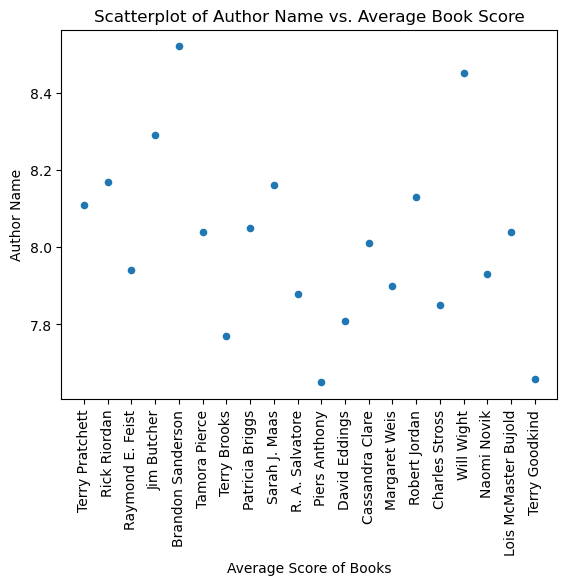

In [165]:
avg_score_df = pd.DataFrame(list(zip(top_authors,score_list)), columns =['author', 'avg_score'])
avg_score_df.plot(kind='scatter',x='author',y='avg_score', legend=False)
plt.xticks(rotation=90)
plt.xlabel("Average Score of Books")
plt.ylabel("Author Name")
plt.title("Scatterplot of Author Name vs. Average Book Score")
plt.show()

<Axes: xlabel='rank'>

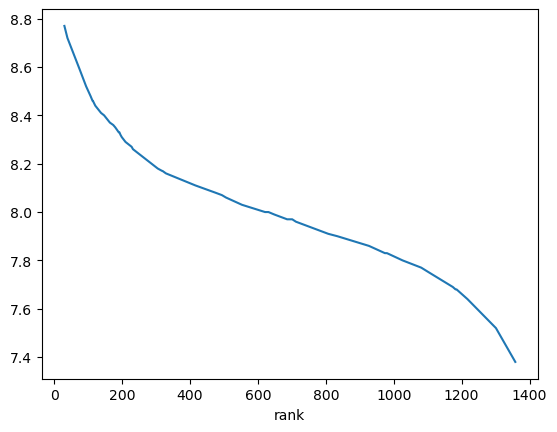

In [177]:
pratchett_df = bookrank_clean_df[bookrank_clean_df.apply(lambda row: row.astype(str).str.contains('Pratchett', case=False).any(), axis=1)]
pratchett_df.plot(x='rank', y='score',legend=False) # did this and then realized it was dumb and obvious

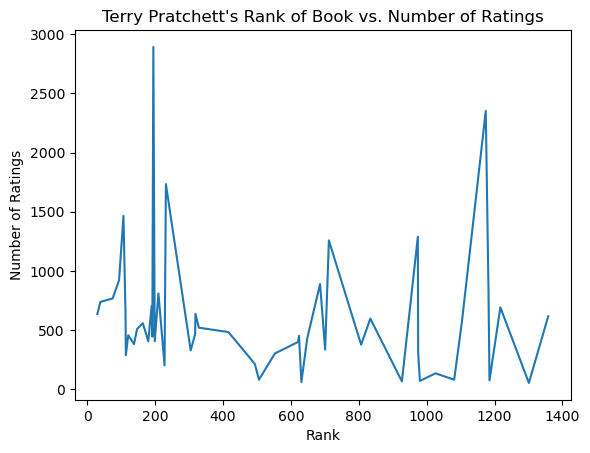

In [203]:
plt.plot(pratchett_df['rank'],pratchett_df['ratings'])
plt.xlabel('Rank')
plt.ylabel('Number of Ratings')
plt.title("Terry Pratchett's Rank of Book vs. Number of Ratings")
plt.show()

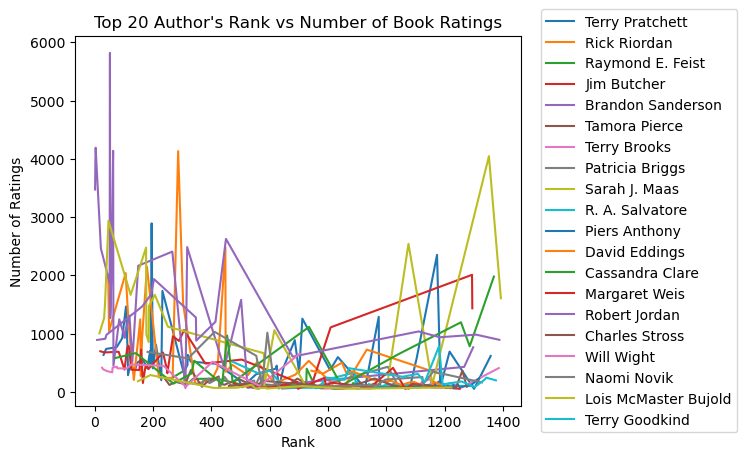

In [211]:
fig, ax = plt.subplots()
for i in range(len(top_authors)):
    test_df = bookrank_clean_df[bookrank_clean_df.apply(lambda row: row.astype(str).str.contains(top_authors[i], case=False).any(), axis=1)]
    plt.plot(test_df['rank'],test_df['ratings'])
ax.legend(top_authors)
ax.set_position([pos.x0, pos.y0, pos.width * 0.9, pos.height])
ax.legend(top_authors,loc='center right', bbox_to_anchor=(1.5, 0.5))
plt.xlabel('Rank')
plt.ylabel('Number of Ratings')
plt.title("Top 20 Author's Rank vs Number of Book Ratings")
plt.show()

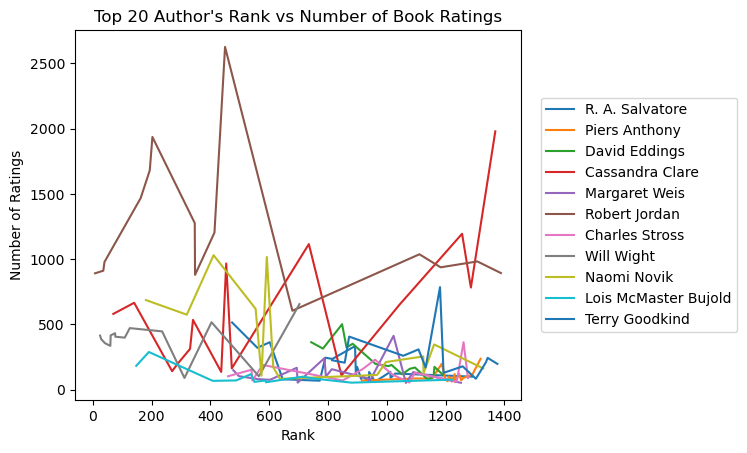

In [220]:
fig, ax = plt.subplots()
for i in range(9, len(top_authors),1):
    test_df = bookrank_clean_df[bookrank_clean_df.apply(lambda row: row.astype(str).str.contains(top_authors[i], case=False).any(), axis=1)]
    plt.plot(test_df['rank'],test_df['ratings'])

ax.set_position([pos.x0, pos.y0, pos.width * 0.9, pos.height])
ax.legend(top_authors[9:20],loc='center right', bbox_to_anchor=(1.5, 0.5))
plt.xlabel('Rank')
plt.ylabel('Number of Ratings')
plt.title("Top 20 Author's Rank vs Number of Book Ratings")
plt.show()